<a href="https://colab.research.google.com/github/priyankamb2725/AI-Projects/blob/main/HERITEGEGPT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q langchain langchain-community langchain-huggingface chromadb sentence-transformers transformers torch

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.0/52.0 kB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 31.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.3/23.3 MB 60.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 278.2/278.2 kB 17.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.6/4.6 MB 85.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 45.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.6/23.6 MB 62.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.5/72.5 kB 5.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 140.1/140.1 kB 9.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.0/60.0 kB 3.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 206.3/206.3 kB 14.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 95.7/95.7 kB 6.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 69.4/69.4 k

In [ ]:
import os

os.makedirs("heritage_documents", exist_ok=True)

documents = {
    "hampi.txt": """
Hampi is a historical and cultural heritage site located in Karnataka, India.
It was the capital of the Vijayanagara Empire and contains numerous temples,
palaces, monuments, markets, and other archaeological remains.

Hampi is known for its distinctive architecture, stone structures, temples,
and historical association with the Vijayanagara Empire.

The Virupaksha Temple is one of the important monuments at Hampi.
Hampi provides important evidence of the history, architecture, culture,
and urban development of the Vijayanagara period.

Source: HeritageGPT Knowledge Base
""",

    "pattadakal.txt": """
Pattadakal is a historical monument complex located in Karnataka, India.
It is well known for its group of temples representing developments in
Indian temple architecture.

The monuments at Pattadakal demonstrate different architectural styles
and are associated with the Chalukya period.

The site is important for understanding the development of temple
architecture and the cultural history of the region.

Source: HeritageGPT Knowledge Base
""",

    "ajanta_caves.txt": """
The Ajanta Caves are a group of rock-cut Buddhist caves located in
Maharashtra, India.

The caves contain important paintings, sculptures, monasteries, and
religious artistic works.

The Ajanta Caves provide valuable information about Buddhist art,
architecture, painting, and religious traditions in ancient India.

Source: HeritageGPT Knowledge Base
""",

    "ellora_caves.txt": """
The Ellora Caves are located in Maharashtra, India.

The complex contains rock-cut monuments associated with Buddhism,
Hinduism, and Jainism.

The caves demonstrate the development of rock-cut architecture and
religious art in India.

Source: HeritageGPT Knowledge Base
""",

    "mysore_palace.txt": """
Mysore Palace is a historic palace located in Mysuru, Karnataka, India.

The palace is associated with the Wadiyar dynasty and is known for
its architecture, decorative interiors, artwork, and cultural importance.

It is an important landmark of Mysuru and is visited for its historical
and architectural significance.

Source: HeritageGPT Knowledge Base
"""
}

for filename, content in documents.items():
    with open(f"heritage_documents/{filename}", "w", encoding="utf-8") as f:
        f.write(content)

print("Heritage documents created successfully.")

Heritage documents created successfully.


In [ ]:
from langchain_community.document_loaders import DirectoryLoader, TextLoader

loader = DirectoryLoader(
    "heritage_documents",
    glob="*.txt",
    loader_cls=TextLoader,
    loader_kwargs={"encoding": "utf-8"}
)

documents = loader.load()

print("Number of documents:", len(documents))

for doc in documents:
    print(doc.metadata["source"])

/tmp/ipykernel_2716/3067453364.py:1: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import DirectoryLoader, TextLoader


Number of documents: 5
heritage_documents/ajanta_caves.txt
heritage_documents/hampi.txt
heritage_documents/mysore_palace.txt
heritage_documents/ellora_caves.txt
heritage_documents/pattadakal.txt


In [ ]:
from langchain_text_splitters import RecursiveCharacterTextSplitter

text_splitter = RecursiveCharacterTextSplitter(
    chunk_size=500,
    chunk_overlap=50
)

chunks = text_splitter.split_documents(documents)

print("Number of chunks:", len(chunks))

Number of chunks: 6


In [ ]:
from langchain_huggingface import HuggingFaceEmbeddings

embeddings = HuggingFaceEmbeddings(
    model_name="sentence-transformers/all-MiniLM-L6-v2"
)

print("Embedding model loaded successfully.")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (4 outputs left out)

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Embedding model loaded successfully.


In [ ]:
from langchain_community.vectorstores import Chroma

vectorstore = Chroma.from_documents(
    documents=chunks,
    embedding=embeddings,
    collection_name="heritagegpt",
    persist_directory="heritage_chroma_db"
)

print("Heritage vector database created successfully.")

Heritage vector database created successfully.


In [ ]:
query = "What is Hampi famous for?"

results = vectorstore.similarity_search(query, k=3)

for i, result in enumerate(results, 1):
    print(f"\n--- Result {i} ---")
    print(result.page_content)
    print("Source:", result.metadata["source"])


--- Result 1 ---
Hampi is a historical and cultural heritage site located in Karnataka, India.
It was the capital of the Vijayanagara Empire and contains numerous temples,
palaces, monuments, markets, and other archaeological remains.

Hampi is known for its distinctive architecture, stone structures, temples,
and historical association with the Vijayanagara Empire.
Source: heritage_documents/hampi.txt

--- Result 2 ---
The Virupaksha Temple is one of the important monuments at Hampi.
Hampi provides important evidence of the history, architecture, culture,
and urban development of the Vijayanagara period.

Source: HeritageGPT Knowledge Base
Source: heritage_documents/hampi.txt

--- Result 3 ---
The Ellora Caves are located in Maharashtra, India.

The complex contains rock-cut monuments associated with Buddhism,
Hinduism, and Jainism.

The caves demonstrate the development of rock-cut architecture and
religious art in India.

Source: HeritageGPT Knowledge Base
Source: heritage_document

In [ ]:
query = "Tell me about the Chalukya architecture."

results = vectorstore.similarity_search(query, k=3)

for result in results:
    print(result.page_content)
    print("-----")

Pattadakal is a historical monument complex located in Karnataka, India.
It is well known for its group of temples representing developments in
Indian temple architecture.

The monuments at Pattadakal demonstrate different architectural styles
and are associated with the Chalukya period.

The site is important for understanding the development of temple
architecture and the cultural history of the region.

Source: HeritageGPT Knowledge Base
-----
The Ellora Caves are located in Maharashtra, India.

The complex contains rock-cut monuments associated with Buddhism,
Hinduism, and Jainism.

The caves demonstrate the development of rock-cut architecture and
religious art in India.

Source: HeritageGPT Knowledge Base
-----
The Ajanta Caves are a group of rock-cut Buddhist caves located in
Maharashtra, India.

The caves contain important paintings, sculptures, monasteries, and
religious artistic works.

The Ajanta Caves provide valuable information about Buddhist art,
architecture, painting, 

In [ ]:
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

model_name = "google/flan-t5-base"

tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSeq2SeqLM.from_pretrained(model_name)

print("FLAN-T5 model loaded successfully.")

tokenizer_config.json:   0%|          | 0.00/2.54k [00:00<?, ?B/s]

spiece.model: reconstructing file:   0%|          |  0.00B /  792kB            

spiece.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/2.42M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/2.20k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  990MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/282 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

FLAN-T5 model loaded successfully.


In [ ]:
def heritagegpt(question):

    results = vectorstore.similarity_search(question, k=3)

    context = "\n\n".join(
        [result.page_content for result in results]
    )

    prompt = f"""
You are HeritageGPT, an AI assistant for cultural heritage.

Answer the question using only the provided heritage context.

Do not invent historical facts.

If the answer is not available in the context, say:
The information is not available in the current HeritageGPT knowledge base.

Heritage Context:
{context}

Question:
{question}

Answer:
"""

    inputs = tokenizer(
        prompt,
        return_tensors="pt",
        truncation=True,
        max_length=1024
    )

    outputs = model.generate(
        **inputs,
        max_new_tokens=200
    )

    answer = tokenizer.decode(
        outputs[0],
        skip_special_tokens=True
    )

    sources = list(
        dict.fromkeys(
            [result.metadata["source"] for result in results]
        )
    )

    return answer, sources

In [ ]:
question = "What is Hampi famous for?"

answer, sources = heritagegpt(question)

print("HERITAGEGPT")
print("=" * 50)
print("Question:", question)

print("\nAnswer:")
print(answer)

print("\nSources:")
for source in sources:
    print("-", source)

HERITAGEGPT
Question: What is Hampi famous for?

Answer:
distinctive architecture, stone structures, temples, and historical association with the Vijayanagara Empire

Sources:
- heritage_documents/hampi.txt
- heritage_documents/ellora_caves.txt


In [ ]:
##################Compuvision##################################

In [ ]:
!pip install -q transformers torch torchvision pillow

In [ ]:
from transformers import pipeline

image_classifier = pipeline(
    "image-classification",
    model="google/vit-base-patch16-224"
)

print("Computer Vision model loaded successfully.")

config.json:   0%|          | 0.00/69.7k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/160 [00:00<?, ?B/s]

Computer Vision model loaded successfully.


Saving Screenshot (169).png to Screenshot (169).png


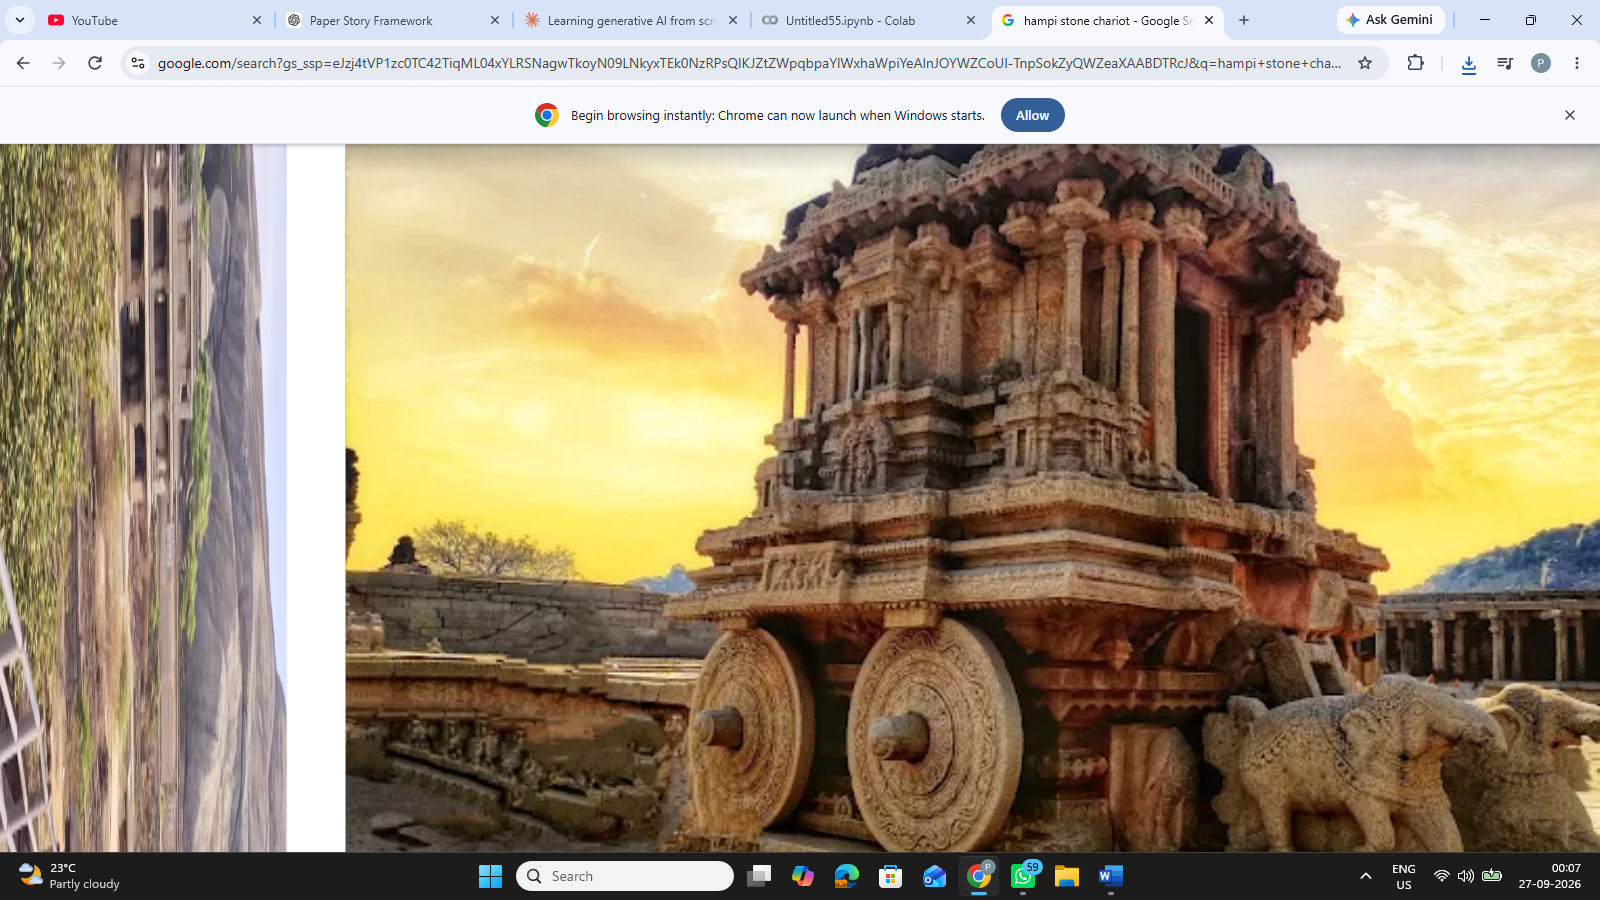

In [ ]:
from google.colab import files
from PIL import Image

uploaded = files.upload()

image_path = list(uploaded.keys())[0]

image = Image.open(image_path).convert("RGB")

display(image)

In [ ]:
results = image_classifier(image)

for result in results[:5]:
    print(result)

{'label': 'web site, website, internet site, site', 'score': 0.9843837022781372}
{'label': 'monitor', 'score': 0.006365242879837751}
{'label': 'screen, CRT screen', 'score': 0.0032042181119322777}
{'label': 'desktop computer', 'score': 0.0008439732482656837}
{'label': 'television, television system', 'score': 0.0007436075247824192}


In [ ]:
def heritagegpt_image(image):

    vision_results = image_classifier(image)

    predicted_name = vision_results[0]["label"]

    question = f"""
Tell me about {predicted_name}.
Include its location, historical importance,
architecture, and cultural significance.
"""

    answer, sources = heritagegpt(question)

    return predicted_name, answer, sources

In [ ]:
predicted_name, answer, sources = heritagegpt_image(image)

print("Identified Heritage:")
print(predicted_name)

print("\nHeritageGPT:")
print(answer)

print("\nSources:")
for source in sources:
    print("-", source)

Identified Heritage:
web site, website, internet site, site

HeritageGPT:
Pattadakal

Sources:
- heritage_documents/ellora_caves.txt
- heritage_documents/mysore_palace.txt
- heritage_documents/pattadakal.txt
